# 06 — Supervised ML: tuning, selection, test
Results produced by `scripts/train_ml.py`; explanation in `docs/05_ml_models.md`.
This notebook only **loads and displays** saved, real outputs — the logic lives in `src/predictops/` and `scripts/`.

In [1]:
import json, pandas as pd
from IPython.display import Image, display, Markdown
from predictops.config import project_path
pd.set_option('display.max_columns', 40)
R = project_path('reports'); F = R / 'figures'
def show(p, w=950):
    display(Image(filename=str(p), width=w))

In [2]:
display(pd.read_csv(R/'ml/validation_selection.csv'))
display(pd.read_csv(R/'ml/test_results_detect.csv'))
display(pd.read_csv(R/'ml/test_results_warning.csv'))

,model,oof_pr_auc,oof_mcc,oof_f1,oof_recall,oof_precision,threshold,params
0,xgboost,0.9992,0.9890,0.9912,0.9871,0.9954,0.5159,"{""subsample"": 0.7, ""n_estimators"": 600, ""min_c..."
1,logreg,0.9992,0.9897,0.9918,0.9889,0.9947,0.7733,"{""penalty"": ""l2"", ""C"": 0.001}"
2,svm,0.9987,0.9884,0.9908,0.9889,0.9926,0.0063,"{""gamma"": 0.01, ""C"": 10.0}"
3,rf,0.9939,0.9890,0.9912,0.9871,0.9954,0.3741,"{""n_estimators"": 100, ""min_samples_leaf"": 50, ..."
4,tree,0.9880,0.9800,0.9841,0.9871,0.9811,0.9707,"{""min_samples_leaf"": 500, ""max_depth"": 4}"


,model,pr_auc,roc_auc,f1,precision,recall,balanced_accuracy,mcc,cohen_kappa,accuracy,brier,fpr,fnr,tp,fp,fn,tn,threshold,event4_detected,event4_lead_time_min,false_alarm_episodes,false_alarms_per_day,train_seconds,inference_ms_per_row,selected
0,logreg,0.0398,0.5808,0.0,0.0,0.0,0.5000,-0.0003,-0.0001,0.9963,0.0038,0.0000,1.0,0,2,270,72379,0.7733,False,NaN,0,0.0000,0.7,0.0004,False
1,tree,0.0456,0.6858,0.0,0.0,0.0,0.5000,0.0000,0.0000,0.9963,0.0039,0.0000,1.0,0,0,270,72381,0.9707,False,NaN,0,0.0000,1.5,0.0003,False
2,rf,0.1629,0.9882,0.0,0.0,0.0,0.5000,0.0000,0.0000,0.9963,0.0035,0.0000,1.0,0,0,270,72381,0.3741,False,NaN,0,0.0000,254.8,0.0009,False
3,svm,0.0031,0.1999,0.0,0.0,0.0,0.4997,-0.0015,-0.0010,0.9957,0.0037,0.0006,1.0,0,42,270,72339,0.0063,False,NaN,1,0.0198,0.6,0.0046,False
4,xgboost,0.4802,0.9853,0.0,0.0,0.0,0.5000,0.0000,0.0000,0.9963,0.0035,0.0000,1.0,0,0,270,72381,0.5159,False,NaN,0,0.0000,3.5,0.0036,True


,horizon_h,model,train_onsets,test_onset,test_positives,test_rows,random_pr_auc,pr_auc,roc_auc
0,2,logreg,"events 2, 3",event 4,120,72382,0.0017,0.0008,0.0213
1,2,xgboost,"events 2, 3",event 4,120,72382,0.0017,0.0017,0.5266
2,6,logreg,"events 2, 3",event 4,361,72382,0.0050,0.0027,0.1643
3,6,xgboost,"events 2, 3",event 4,361,72382,0.0050,0.0028,0.1861
4,12,logreg,"events 2, 3",event 4,720,72382,0.0099,0.0053,0.0965
5,12,xgboost,"events 2, 3",event 4,720,72382,0.0099,0.0067,0.3221


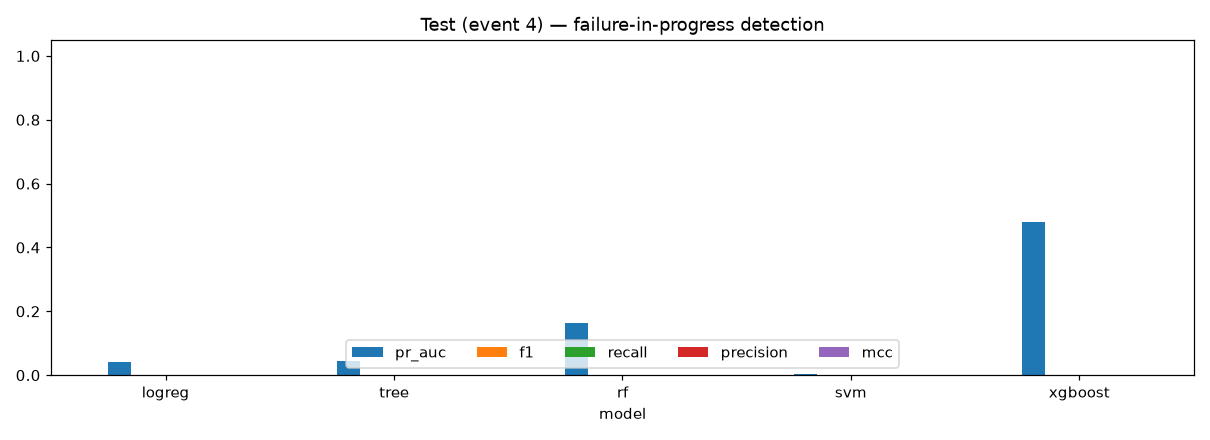

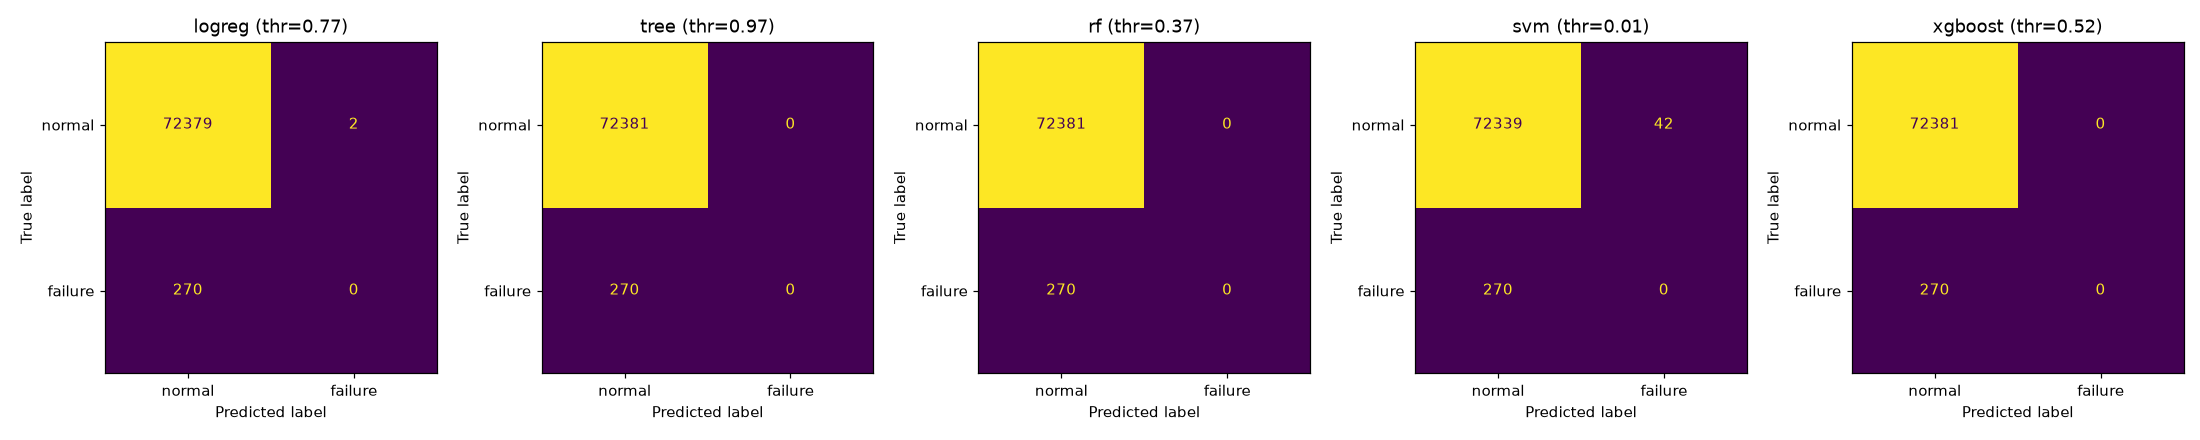

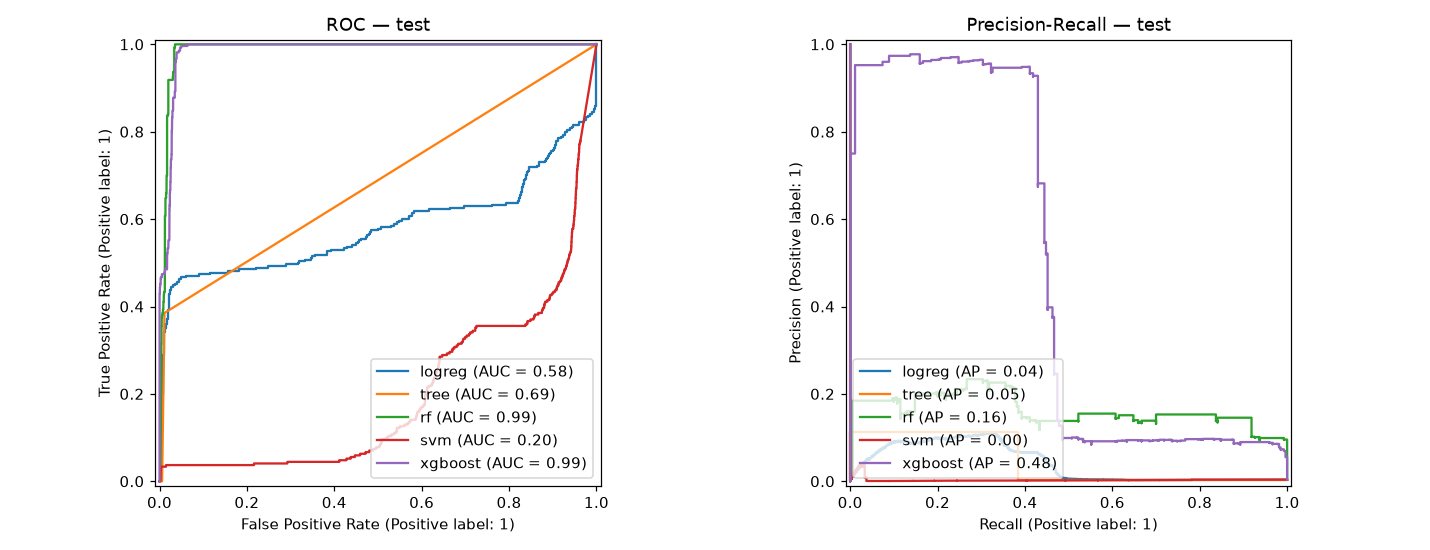

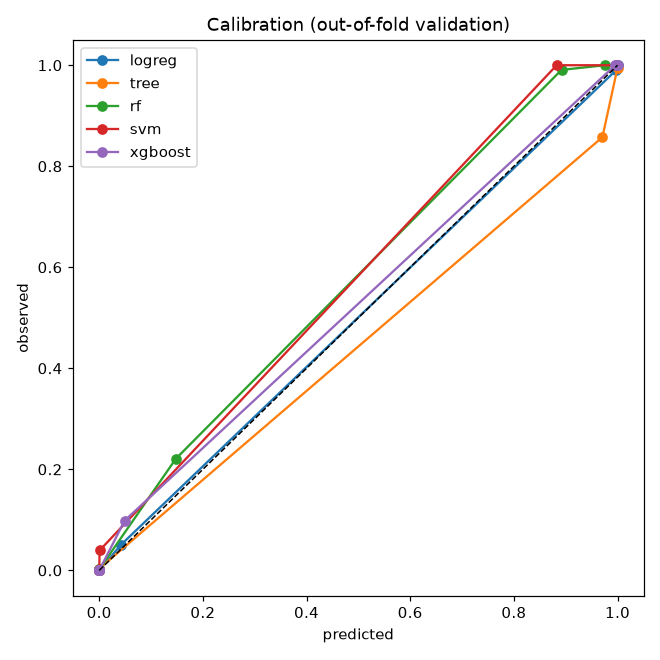

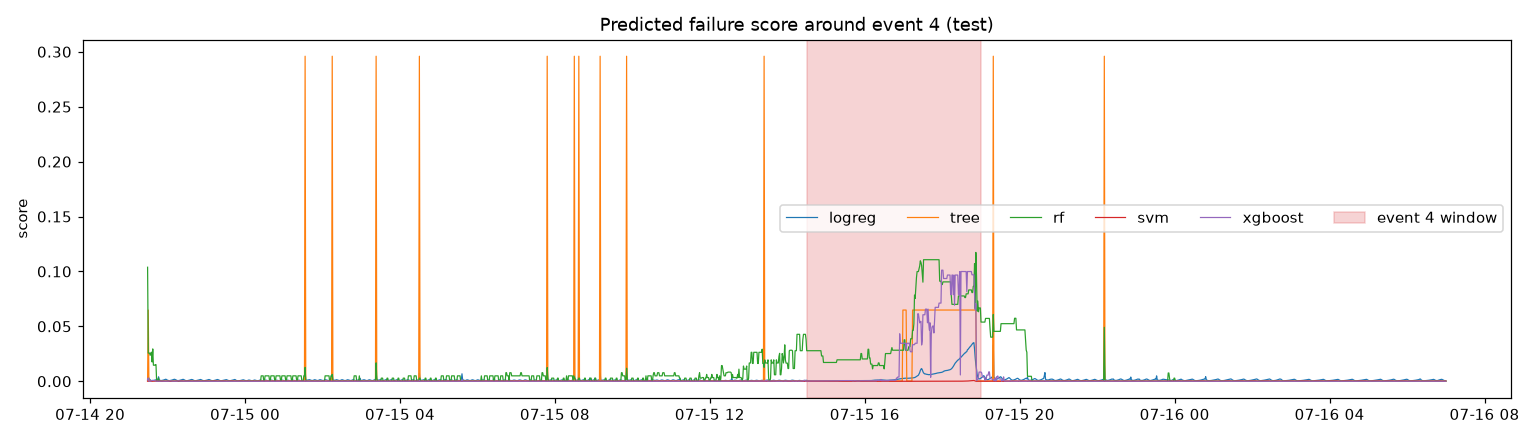

In [3]:
for f in ['test_comparison','test_confusion_matrices','test_roc_pr','calibration_oof','test_event4_scores']: show(F/f'ml/{f}.png')